Archived output integrity: PASS
Verified files: 7


### Figure 01 Architectures

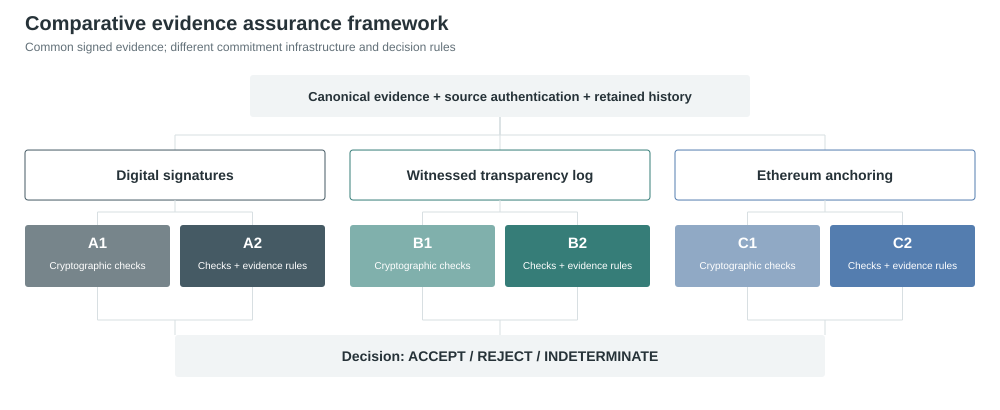

### Figure 02 Experimental Design

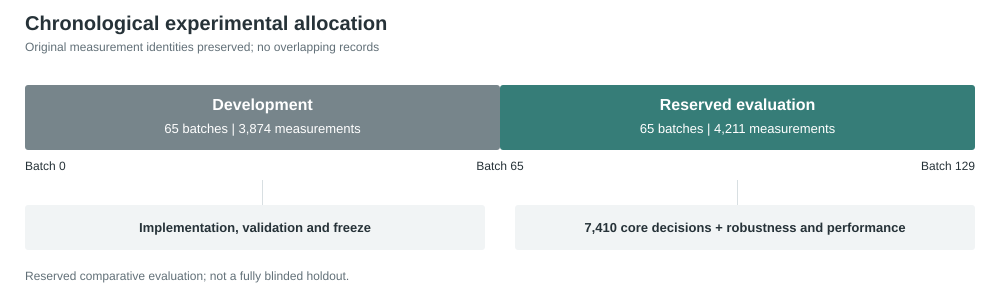

### Figure 03 Decision Reliability

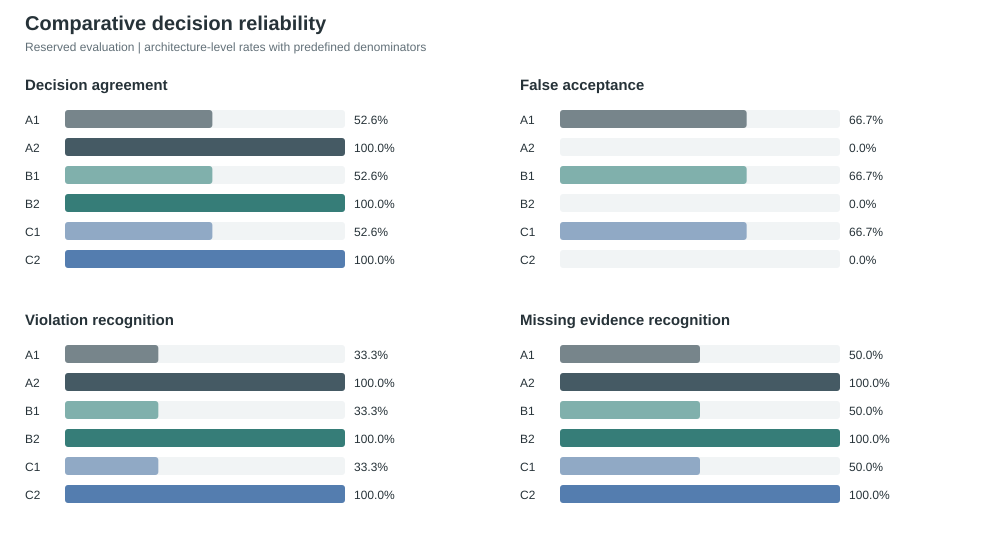

### Figure 04 Witness Sensitivity

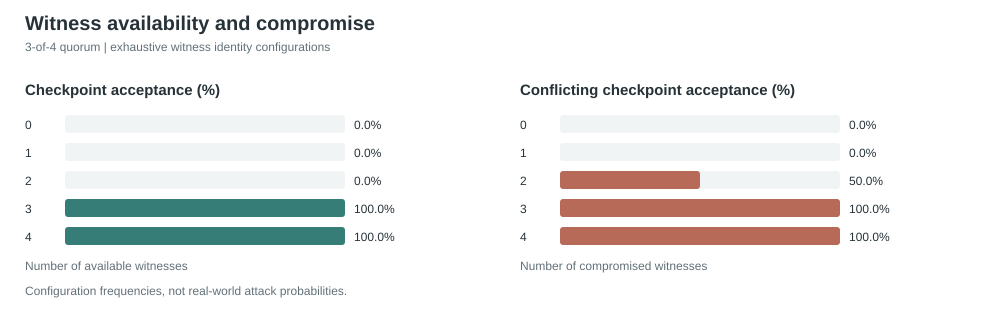

### Figure 05 Conflicting Evidence

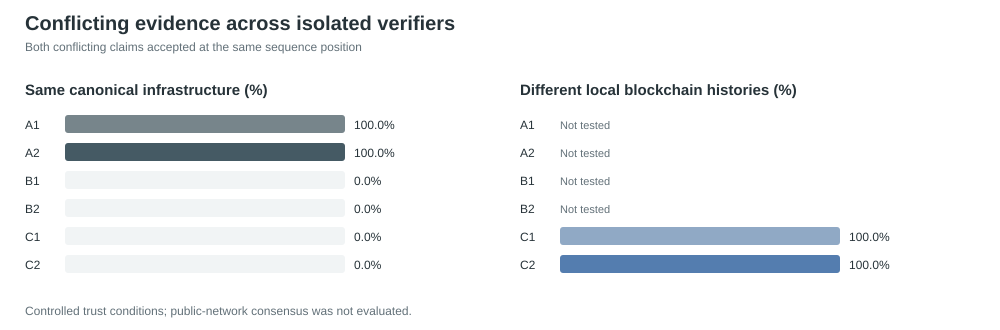

### Figure 06 Verification Cost

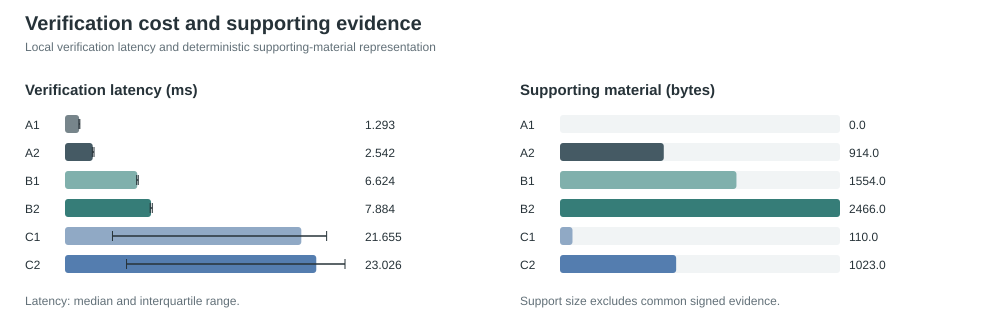


Figures displayed: 6
Existing research outputs modified: 0
VALIDATION: PASS


In [1]:
# ============================================================
# CELL 32 — Publication figure display and integrity verification
# ============================================================
# Display the archived publication figures without modifying
# the frozen evaluation results.

from pathlib import Path
import hashlib
from IPython.display import display, SVG, Markdown

ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "EVALUATION_FREEZE.json").is_file()
)

RESULTS = ROOT / "results" / "reserved_evaluation"

manifest = {}

for line in (RESULTS / "SHA256SUMS").read_text().splitlines():

    digest, filename = line.split(maxsplit=1)
    manifest[filename.strip()] = digest

# Verify all archived outputs before display.
for filename, expected_digest in manifest.items():

    actual_digest = hashlib.sha256(
        (RESULTS / filename).read_bytes()
    ).hexdigest()

    assert actual_digest == expected_digest, filename

print("Archived output integrity: PASS")
print("Verified files:", len(manifest))

# Display all publication figures in the notebook.
figure_paths = sorted(RESULTS.glob("figure_*.svg"))

assert len(figure_paths) == 6

for path in figure_paths:

    display(Markdown(
        "### " + path.stem.replace("_", " ").title()
    ))

    display(SVG(filename=str(path)))

print("\nFigures displayed:", len(figure_paths))
print("Existing research outputs modified: 0")
print("VALIDATION: PASS")

In [2]:
# ============================================================
#  Ethereum backend latency diagnosis
# ============================================================
# Isolate backend operations using the frozen contract.
# Do not modify original experiments or archived outputs.

import ast
import json
import hashlib
import inspect
from pathlib import Path
from statistics import median
from time import perf_counter_ns
from importlib.metadata import version
from eth_tester.exceptions import BlockNotFound, TransactionNotFound


def diagnose_ethereum_latency():

    root = next(
        p for p in (Path.cwd(), *Path.cwd().parents)
        if (p / "EVALUATION_FREEZE.json").is_file()
    )

    freeze = json.loads(
        (root / "EVALUATION_FREEZE.json").read_text()
    )

    notebook_path = (
        root / "notebooks/02_benchmark_development.ipynb"
    )

    assert hashlib.sha256(
        notebook_path.read_bytes()
    ).hexdigest() == freeze["development_notebook_sha256"]

    notebook = json.loads(notebook_path.read_text())

    sources = [
        "".join(cell["source"])
        for cell in notebook["cells"]
        if cell["cell_type"] == "code"
        and "".join(cell["source"]).strip()
    ]

    # Load only the frozen contract implementation,
    # excluding the original development experiments.
    namespace = {
        "ROOT": root,
        "json": json,
        "BlockNotFound": BlockNotFound,
        "TransactionNotFound": TransactionNotFound,
    }

    contract_source = sources[6].split(
        "ethereum_anchor = EthereumAnchor()", 1
    )[0]

    exec(contract_source, namespace)

    # Load the original temporally restricted ledger classes.
    for source in sources:

        for node in ast.parse(source).body:

            if isinstance(node, ast.ClassDef) and node.name in (
                "RestrictedLedger",
                "TemporalEthereumView",
            ):

                exec(
                    ast.get_source_segment(source, node),
                    namespace,
                )

    anchor = namespace["EthereumAnchor"]()
    temporal_view = namespace["TemporalEthereumView"]

    print("=== DIAGNOSTIC ENVIRONMENT ===")
    print("Frozen implementation: VERIFIED")
    print("eth-tester:", version("eth-tester"))
    print("py-evm:", version("py-evm"))

    # Reproduce the original history length using
    # explicitly synthetic commitments.
    total = (
        freeze["development_batch_count"]
        + freeze["evaluation_batch_count"]
    )

    commitments = []
    receipts = []
    previous = bytes(32)

    for sequence in range(total):

        commitment = hashlib.sha256(
            f"diagnostic-{sequence}".encode()
        ).digest()

        receipt = anchor.append(
            sequence, commitment, previous
        )

        assert receipt["status"] == 1

        commitments.append(commitment)
        receipts.append(receipt)

        previous = commitment

    assert anchor.count() == total

    tip = anchor.tester.get_block_by_number(
        "latest"
    )["number"]

    print("Synthetic commitments:", total)
    print("Canonical tip:", tip)

    # Use the same warm-up and repetition counts
    # as the approved performance protocol.
    def measure(operation):

        for _ in range(freeze["timing_warmups"]):
            operation()

        timings = []

        for _ in range(freeze["timing_repetitions"]):

            start = perf_counter_ns()
            operation()
            timings.append(
                perf_counter_ns() - start
            )

        return median(timings) / 1_000_000

    results = []

    print("\n=== COMPONENT LATENCY (ms) ===")

    print(
        f"{'Batch':>5} {'Age':>5} "
        f"{'Count':>8} {'Storage':>8} "
        f"{'Tx':>8} {'Receipt':>8} {'Block':>8}"
    )

    for sequence in freeze["evaluation_batch_indices"]:

        receipt = receipts[sequence]
        block_number = receipt["block_number"]
        tx_hash = receipt["transaction_hash"]

        view = temporal_view(anchor, block_number)

        assert view.commitment_at(sequence) == (
            commitments[sequence]
        )

        operations = {
            "count": lambda: view.count(),

            "storage": lambda: view.query(
                "commitments(uint256)",
                "bytes32",
                ["uint256"],
                [sequence],
            ),

            "transaction": lambda:
                view.tester.get_transaction_by_hash(tx_hash),

            "receipt": lambda:
                view.tester.get_transaction_receipt(tx_hash),

            "block": lambda:
                view.tester.get_block_by_number(block_number),
        }

        timings = {
            name: measure(operation)
            for name, operation in operations.items()
        }

        results.append({
            "sequence": sequence,
            "block_age": tip - block_number,
            **timings,
        })

        print(
            f"{sequence:>5} {tip-block_number:>5} "
            + " ".join(
                f"{value:>8.4f}"
                for value in timings.values()
            )
        )

    # Inspect the actual installed backend source.
    backend = anchor.tester.backend

    print("\n=== INSTALLED BACKEND IMPLEMENTATION ===")

    for name in (
        "get_transaction_by_hash",
        "get_transaction_receipt",
    ):

        method = getattr(backend, name)

        print(f"\n--- {name} ---")
        print(inspect.getsource(method))

    module = inspect.getmodule(type(backend))

    helper = getattr(
        module, "_get_transaction_by_hash", None
    )

    if helper is not None:
        print("\n--- Transaction lookup helper ---")
        print(inspect.getsource(helper))

    assert anchor.count() == total
    assert anchor.head() == commitments[-1]

    print("\n=== DIAGNOSTIC VALIDATION ===")
    print("Diagnostic batches:", len(results))
    print("Original experiments rerun: 0")
    print("Research files modified: 0")
    print("VALIDATION: PASS")


diagnose_ethereum_latency()

=== DIAGNOSTIC ENVIRONMENT ===
Frozen implementation: VERIFIED
eth-tester: 0.14.0b1
py-evm: 0.12.1b1
Synthetic commitments: 130
Canonical tip: 131

=== COMPONENT LATENCY (ms) ===
Batch   Age    Count  Storage       Tx  Receipt    Block
   65    64   0.9991   1.1124  11.1731  11.1578   0.1405
   66    63   0.9961   1.1236  11.0796  11.1343   0.1481
   67    62   1.0406   1.1260  11.2200  11.2330   0.1415
   68    61   0.9950   1.1184  11.1537  11.2202   0.1441
   69    60   1.0026   1.1195  10.9235  11.5655   0.1416
   70    59   0.9897   1.0920  10.8888  10.7420   0.1445
   71    58   1.0491   1.1079  10.6058  10.7160   0.1395
   72    57   0.9948   1.1096  10.8012  10.8505   0.1447
   73    56   1.0035   1.1045  10.4555  10.5520   0.1402
   74    55   0.9924   1.1160  11.9946  10.7767   0.1463
   75    54   0.9962   1.1194  10.4485  10.5177   0.1432
   76    53   0.9965   1.1091  10.4635  10.4967   0.1468
   77    52   1.0424   1.1029  10.2306  10.3021   0.1380
   78    51   0.9916   

### Figure 01 Architectures

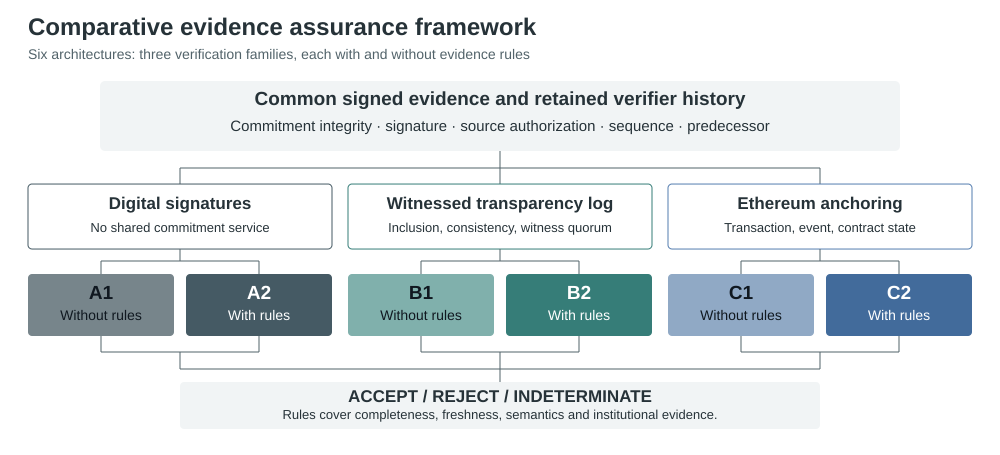

### Figure 02 Experimental Design

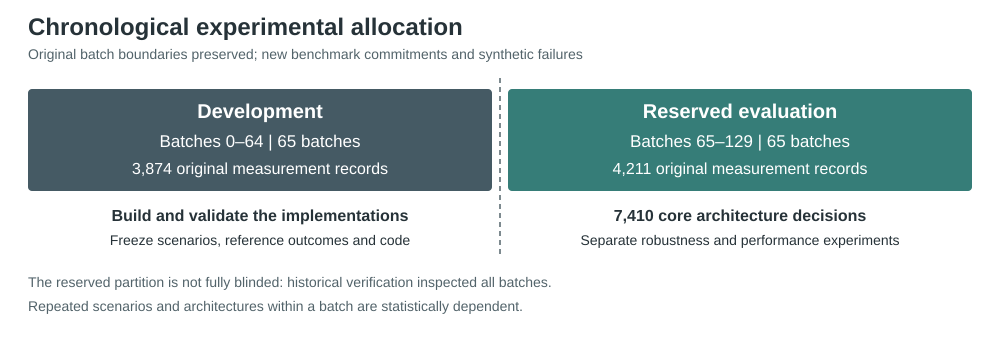

### Figure 03 Decision Reliability

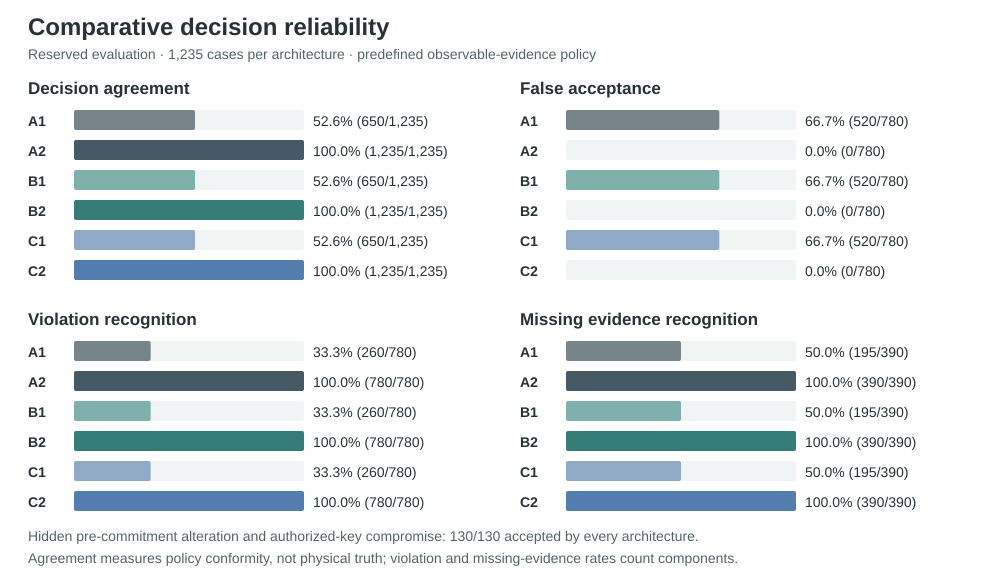

### Figure 04 Witness Sensitivity

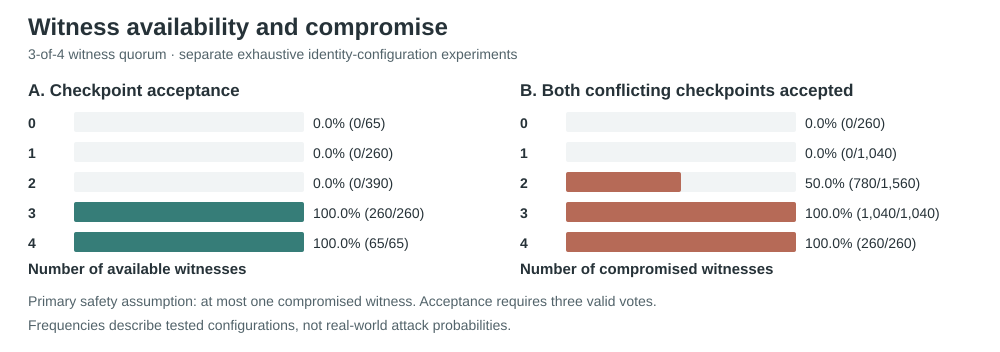

### Figure 05 Conflicting Evidence

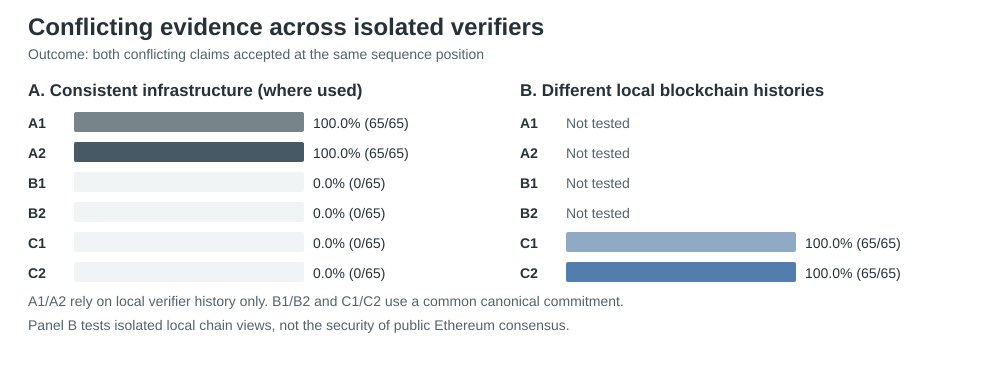

### Figure 06 Verification Cost

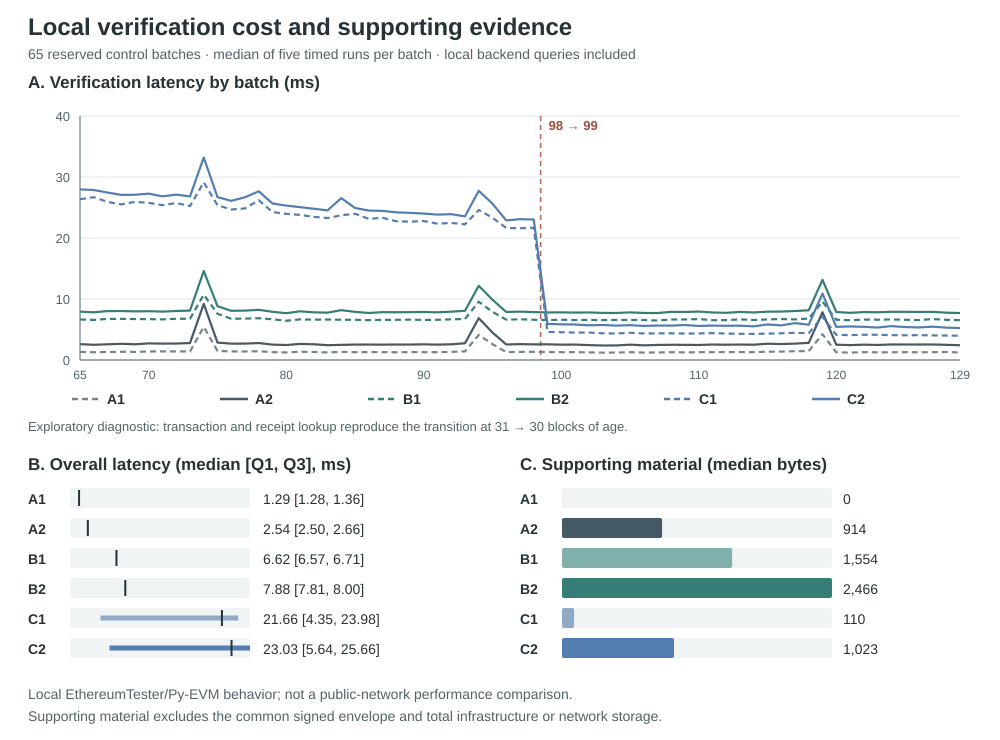


=== PUBLICATION FINALIZATION ===
Original results SHA-256: 67f8b8c62f03c21f1b0382f9fbf94584c5037391fad0f3f92dba8dcd3e680f61
Scientific results unchanged: PASS
Original figure set retained in Git: abff7ab
Active figures: 6
Obsolete active figure copies: 0
Updated manifest: PASS (7/7)
Original experiments rerun: 0
VALIDATION: PASS


In [5]:
# ============================================================
# CELL 34 — Final publication figures and output verification
# ============================================================

from pathlib import Path
import runpy

ROOT = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "EVALUATION_FREEZE.json").is_file()
)

module = runpy.run_path(
    str(ROOT / "tools/finalize_publication_figures.py")
)

module["finalize_publication_figures"](ROOT)